In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")
else:
    print("⚠️ No GPU detected — go to Runtime > Change runtime type > T4 GPU")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 15.64 GB


In [ ]:
!pip install open3d wandb tqdm huggingface_hub tqdm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 28.3 MB/s eta 0:00:00


In [ ]:
import json
import os
import glob
import zipfile
import random
import numpy as np
import open3d as o3d
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import wandb
from huggingface_hub import hf_hub_download
import json
import plotly.graph_objects as go
from openai import OpenAI
from google.colab import userdata

In [ ]:
os.makedirs("data", exist_ok=True)

data_dir= "data/MaizeField"
print(" Downloading raw point clouds (10k points per plant)...")

zip_path = hf_hub_download(
    repo_id="BGLab/MaizeField3D",
    filename="datasets/FielGrwon_ZeaMays_RawPCD_10k.zip",
    repo_type="dataset",
    local_dir="data"
)

print(" Extracting...")

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(data_dir)

ply_files = sorted(glob.glob(f"{data_dir}/**/*.ply", recursive=True))

print(f" Found {len(ply_files)} plant files.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


datasets/FielGrwon_ZeaMays_RawPCD_10k.zi(…):   0%|          | 0.00/218M [00:00<?, ?B/s]

 Extracting...
 Found 1045 plant files.


In [ ]:
all_ply_files = sorted(glob.glob(f"{CFG['data_dir']}/**/*.ply", recursive=True))
print(f"Found {len(all_ply_files)} total plant files.")

# ── Take exactly 150, split 120/30 ──
random.seed(42)
random.shuffle(all_ply_files)
all_ply_files = all_ply_files[:150]

train_files = all_ply_files[:120]
test_files  = all_ply_files[120:]
print(f"Train: {len(train_files)}  Test: {len(test_files)}")

Found 1045 total plant files.
Train: 120  Test: 30


In [ ]:
wandb.login()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: captainyagami08 (captainyagami08-tybi) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [ ]:
CFG = {
    "data_dir":             "data/MaizeField",
    "num_points":           1024,
    "batch_size":           8,
    "epochs":               150,       # ← changed from 200
    "lr":                   1e-4,
    "latent_dim":           256,
    "k":                    16,
    "subset_size":          150,       # ← changed from 1045
    "train_size":           120,       # ← fixed 120 train
    "test_size":            30,        # ← fixed 30 test
    "checkpoint_interval":  25,
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

Device: cuda


In [ ]:
def normalize_pc(pc):
    pc = pc - pc.mean(axis=0)
    scale = np.sqrt((pc**2).sum(axis=1)).max()
    pc = pc / (scale + 1e-8)
    return pc

def sample_points(pc, n):
    if pc.shape[0] >= n:
        idx = np.random.choice(pc.shape[0], n, replace=False)
    else:
        idx = np.random.choice(pc.shape[0], n, replace=True)
    return pc[idx]

In [ ]:
class MaizeDataset(Dataset):
    def __init__(self, files):
        self.files = files

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        pcd    = o3d.io.read_point_cloud(self.files[idx])
        points = np.asarray(pcd.points)

        # ── Clean NaN/Inf ──
        mask   = np.isfinite(points).all(axis=1)
        points = points[mask]

        points = normalize_pc(points)
        points = sample_points(points, CFG["num_points"])
        return torch.tensor(points, dtype=torch.float32)

train_dataset = MaizeDataset(train_files)
test_dataset  = MaizeDataset(test_files)

train_loader  = DataLoader(train_dataset, batch_size=CFG["batch_size"], shuffle=True,  num_workers=2)
test_loader   = DataLoader(test_dataset,  batch_size=CFG["batch_size"], shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}  Test batches: {len(test_loader)}")

Train batches: 15  Test batches: 4


In [ ]:
def knn(x, k):
    inner = -2 * torch.matmul(x.transpose(2,1), x)
    xx    = torch.sum(x**2, dim=1, keepdim=True)
    pairwise_distance = -xx - inner - xx.transpose(2,1)
    return pairwise_distance.topk(k=k, dim=-1)[1]

def get_graph_feature(x, k=20):
    batch_size = x.size(0)
    num_points = x.size(2)
    idx        = knn(x, k)
    device     = x.device
    idx_base   = torch.arange(0, batch_size, device=device).view(-1,1,1) * num_points
    idx        = (idx + idx_base).view(-1)
    x          = x.transpose(2,1).contiguous()
    feature    = x.view(batch_size*num_points, -1)[idx, :]
    feature    = feature.view(batch_size, num_points, k, -1)
    x          = x.view(batch_size, num_points, 1, -1).repeat(1,1,k,1)
    feature    = torch.cat((feature-x, x), dim=3).permute(0,3,1,2)
    return feature

class DGCNN_Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(6,64,1),   nn.BatchNorm2d(64),  nn.LeakyReLU(0.2))
        self.conv2 = nn.Sequential(nn.Conv2d(128,128,1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2))
        self.conv3 = nn.Sequential(nn.Conv2d(256,256,1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2))
        self.fc    = nn.Linear(256, CFG["latent_dim"])

    def forward(self, x):
        x  = x.transpose(2,1)
        x  = get_graph_feature(x, CFG["k"])
        x  = self.conv1(x)
        x1 = x.max(dim=-1)[0]
        x  = get_graph_feature(x1, CFG["k"])
        x  = self.conv2(x)
        x2 = x.max(dim=-1)[0]
        x  = get_graph_feature(x2, CFG["k"])
        x  = self.conv3(x)
        x3 = x.max(dim=-1)[0]
        x  = x3.max(dim=-1)[0]
        return self.fc(x)

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(CFG["latent_dim"], 512), nn.ReLU(),
            nn.Linear(512, 1024),              nn.ReLU(),
            nn.Linear(1024, CFG["num_points"]*3)
        )

    def forward(self, z):
        return self.mlp(z).view(-1, CFG["num_points"], 3)

class PointAutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = DGCNN_Encoder()
        self.decoder = Decoder()

    def forward(self, x):
        z     = self.encoder(x)
        recon = self.decoder(z)
        return recon

def chamfer_loss(pc1, pc2):
    diff  = pc1.unsqueeze(2) - pc2.unsqueeze(1)
    dist  = torch.sum(diff**2, dim=-1)
    loss1 = dist.min(dim=2)[0].mean()
    loss2 = dist.min(dim=1)[0].mean()
    return loss1 + loss2

print("✅ Model defined")

✅ Model defined


In [ ]:
wandb.login()

wandb.init(
    project = "maize-pointcloud",
    name    = "dgcnn-150plants-150epochs",
    config  = CFG
)

model     = PointAutoEncoder().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])

train_losses = []
test_losses  = []

for epoch in range(CFG["epochs"]):

    # ── Train ──
    model.train()
    total_loss = 0
    for pc in tqdm(train_loader, desc=f"Epoch {epoch+1}/{CFG['epochs']}"):
        pc    = pc.to(DEVICE)
        recon = model(pc)
        loss  = chamfer_loss(pc, recon)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_train_loss = total_loss / len(train_loader)

    # ── Test ──
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for pc in test_loader:
            pc    = pc.to(DEVICE)
            recon = model(pc)
            test_loss += chamfer_loss(pc, recon).item()
    avg_test_loss = test_loss / len(test_loader)

    train_losses.append(avg_train_loss)
    test_losses.append(avg_test_loss)

    log_train = np.log(avg_train_loss) if avg_train_loss > 0 else float('-inf')
    log_test  = np.log(avg_test_loss)  if avg_test_loss  > 0 else float('-inf')

    print(f"Epoch {epoch+1:3d} | Train {avg_train_loss:.6f} (log {log_train:.4f}) | Test {avg_test_loss:.6f} (log {log_test:.4f})")

    wandb.log({
        "epoch":           epoch + 1,
        "train_loss":      avg_train_loss,
        "test_loss":       avg_test_loss,
        "log_train_loss":  log_train,
        "log_test_loss":   log_test,
    })

    if (epoch + 1) % CFG["checkpoint_interval"] == 0:
        torch.save(model.state_dict(), f"checkpoint_epoch_{epoch+1}.pth")
        print(f"  ✅ Checkpoint saved at epoch {epoch+1}")

wandb.finish()
print("\n✅ Training complete")

wandb: WARNING Calling wandb.login() after wandb.init() has no effect.


epoch,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇██
lr,██████████████▄▄▄▄▄▄▄▄▄▄▄▄▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+2,...
epoch,117
lr,0.00049
test_CD,nan
train_CD,nan


Epoch 1/150: 100%|██████████| 15/15 [00:01<00:00,  8.09it/s]


Epoch   1 | Train 0.025980 (log -3.6504) | Test 0.154662 (log -1.8665)


Epoch 2/150: 100%|██████████| 15/15 [00:01<00:00, 11.82it/s]


...

Epoch 149 | Train 0.002163 (log -6.1362) | Test 0.007106 (log -4.9468)


Epoch 150/150: 100%|██████████| 15/15 [00:01<00:00, 11.40it/s]


Epoch 150 | Train 0.002080 (log -6.1752) | Test 0.007035 (log -4.9569)
  ✅ Checkpoint saved at epoch 150


epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇████
log_test_loss,██▅▆▅▅▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▂▁▁▁▁▂▁▁▁▁▁▁▁▁▁
log_train_loss,█▇▇▆▆▆▆▆▅▅▅▄▄▄▄▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁
test_loss,█▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss,█▅▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,150
log_test_loss,-4.9569
log_train_loss,-6.17521
test_loss,0.00703
train_loss,0.00208



✅ Training complete


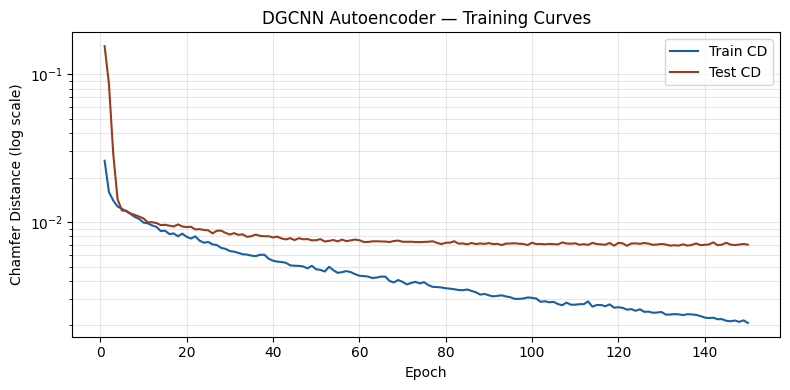

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 4))
plt.semilogy(epochs, train_losses, label='Train CD', color='#185FA5')
plt.semilogy(epochs, test_losses,  label='Test CD',  color='#993C1D')
plt.xlabel('Epoch')
plt.ylabel('Chamfer Distance (log scale)')
plt.title('DGCNN Autoencoder — Training Curves')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def visualize_reconstruction_plotly(model, dataset, device, num_samples=3):
    model.eval()
    for i in range(num_samples):
        idx   = np.random.randint(len(dataset))
        pc    = dataset[idx].unsqueeze(0).to(device)
        with torch.no_grad():
            recon = model(pc)
        pc    = pc.squeeze().cpu().numpy()
        recon = recon.squeeze().cpu().numpy()

        fig = make_subplots(
            rows=1, cols=2,
            specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]],
            subplot_titles=(f"Original (Sample {i+1})", f"Reconstruction (Sample {i+1})")
        )
        fig.add_trace(go.Scatter3d(
            x=pc[:,0], y=pc[:,1], z=pc[:,2], mode="markers",
            marker=dict(size=2, color=pc[:,2], colorscale="Viridis", opacity=0.8),
            name="Original"), row=1, col=1)
        fig.add_trace(go.Scatter3d(
            x=recon[:,0], y=recon[:,1], z=recon[:,2], mode="markers",
            marker=dict(size=2, color=recon[:,2], colorscale="Plasma", opacity=0.8),
            name="Reconstruction"), row=1, col=2)
        fig.update_layout(title=f"DGCNN Autoencoder — Sample {i+1}", height=500)
        fig.show()

visualize_reconstruction_plotly(model, train_dataset, DEVICE, num_samples=3)

In [ ]:
with open("selected_plants.txt", "w") as f:
    for path in all_ply_files:
        f.write(path + "\n")

In [ ]:
import time
import numpy as np
from scipy.spatial import KDTree

# ── F-Score function ──
def fscore(pred, gt, tau=None):
    if tau is None:
        diag = np.linalg.norm(gt.max(axis=0) - gt.min(axis=0))
        tau  = 0.01 * diag
    tree_gt   = KDTree(gt)
    tree_pred = KDTree(pred)
    d_pred, _ = tree_gt.query(pred)
    precision  = (d_pred < tau).mean()
    d_gt, _   = tree_pred.query(gt)
    recall     = (d_gt < tau).mean()
    if precision + recall < 1e-8:
        return 0.0, 0.0, 0.0
    f = 2 * precision * recall / (precision + recall)
    return float(precision), float(recall), float(f)

def chamfer_numpy(pred, gt):
    d1 = KDTree(gt).query(pred)[0].mean()
    d2 = KDTree(pred).query(gt)[0].mean()
    return d1 + d2

# ── Evaluate on test set ──
model.eval()
cd_scores, f_scores, prec_scores, rec_scores, latents = [], [], [], [], []

start_time = time.time()

with torch.no_grad():
    for pc in test_loader:
        pc    = pc.to(DEVICE)
        recon = model(pc)
        z     = model.encoder(pc)

        for i in range(pc.shape[0]):
            gt_np   = pc[i].cpu().numpy()
            pred_np = recon[i].cpu().numpy()

            cd = chamfer_numpy(pred_np, gt_np)
            p, r, f = fscore(pred_np, gt_np)

            cd_scores.append(cd)
            f_scores.append(f)
            prec_scores.append(p)
            rec_scores.append(r)
            latents.append(z[i].cpu().numpy())

training_time = time.time() - start_time  # inference time here; add manually for training

cd_scores  = np.array(cd_scores)
f_scores   = np.array(f_scores)
latents    = np.array(latents)

print("="*50)
print(f"CD mean:       {cd_scores.mean():.6f}")
print(f"CD std:        {cd_scores.std():.6f}")
print(f"F-Score mean:  {f_scores.mean():.4f}")
print(f"Precision:     {np.array(prec_scores).mean():.4f}")
print(f"Recall:        {np.array(rec_scores).mean():.4f}")
print("="*50)

# ── Save for compare later ──
np.save("dgcnn_cd_scores.npy",  cd_scores)
np.save("dgcnn_f_scores.npy",   f_scores)
np.save("dgcnn_latents.npy",    latents)
print("✅ Saved cd_scores, f_scores, latents")

CD mean:       0.091407
CD std:        0.016116
F-Score mean:  0.2516
Precision:     0.3187
Recall:        0.2126
✅ Saved cd_scores, f_scores, latents
